# 02 · Module 1: intensity-aware and directional 1D–2D agreement

**Research question 1.** Do the 1D signal CNN and the 2D image CNN explain the same recording with the same temporal evidence, and is their agreement above chance?

**Method.** Both Grad-CAM maps are placed on one 600-column time grid (536 valid waveform columns).
The 2D map is projected onto the waveform with an explicit kernel that weights but never replaces its intensity,
$g_2(u)=\sum_y H(y,u)K(y,u)/\sum_y K(y,u)$, here an on-trace corridor of $\pm 6$ px (the projection used by Modules 2 and 3).
Each map is normalised to attribution mass, $p_u=g_1(u)/\sum g_1$, $q_u=g_2(u)/\sum g_2$, and compared with

* shared mass $O=\sum_u \min(p_u,q_u)$, weighted Jaccard $J_w=O/(2-O)$, total variation $1-O$,
* Spearman $\rho_s$, top-15 % Dice (chance level $k/T=0.15$),
* direction $r_u=(p_u-q_u)/(p_u+q_u)$, gated $|r_u|>1/3$ (one branch carries at least twice the mass) on the union of salient columns,
* normalised entropy of each map (1 = flat).

Every statistic is compared with a **within-class mispairing null**: the 1D map of one recording is paired with the 2D map of another recording of the same class.

**Comparative baseline.** The anchor-style binary-mask (min–max) agreement from the Module 1 branch is evaluated at the end.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd().resolve().parent          # repository root (notebooks/ is one level down)
sys.path.insert(0, str(ROOT / 'src'))
ARCH = ROOT / 'data' / 'archived'           # archived HPC outputs (inputs of this notebook)
TAB = ROOT / 'results' / 'tables'           # tables written by the notebooks
FIG = ROOT / 'results' / 'figures'          # figures written by the notebooks (used in the report)
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40); pd.set_option('display.precision', 4)
warnings.filterwarnings('ignore', category=RuntimeWarning)
CLASSES = ['AFib', 'GSVT', 'SB', 'SR']
def show(name, width=900):
    """Display a figure that a plotting function saved to results/figures."""
    display(Image(filename=str(FIG / f'{name}.png'), width=width))
print('repository root:', ROOT.name)

repository root: DAN-MMGradCAM


In [2]:
from scipy.stats import spearmanr, kruskal
EPS, TOP, GATE, N_NULL, N_BOOT, SEED = 1e-12, 0.15, 1/3, 20, 2000, 20261117
rng = np.random.default_rng(SEED)

def mass(x):
    x = np.clip(np.nan_to_num(np.asarray(x, float)), 0, None); s = x.sum()
    return None if s <= EPS else x / s

def topk(x, f):
    k = max(1, int(np.ceil(f * x.size))); s = np.zeros(x.size, bool)
    s[np.argsort(-x, kind='stable')[:k]] = True; return s

def entropy_norm(p):
    nz = p[p > 0]; return float(-(nz * np.log(nz)).sum() / np.log(p.size))

def agreement(p, q):
    """Module 1 agreement between two attribution-mass vectors on the same time grid."""
    O = float(np.minimum(p, q).sum()); a, b = topk(p, TOP), topk(q, TOP)
    r = (p - q) / (p + q + EPS); sal = a | b
    return {'O': O, 'Jw': O / (2 - O), 'TV': 1 - O, 'spearman': float(spearmanr(p, q).statistic),
            'dice15': 2 * (a & b).sum() / (a.sum() + b.sum()), 'chance_dice': a.sum() / p.size,
            'dir_1D_dominant': 100 * np.mean(sal & (r > GATE)), 'dir_2D_dominant': 100 * np.mean(sal & (r < -GATE)),
            'dir_balanced': 100 * np.mean(sal & (np.abs(r) <= GATE)),
            'entropy_1D': entropy_norm(p), 'entropy_2D': entropy_norm(q)}

def boot_ci(x, stat=np.median):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    b = [stat(rng.choice(x, x.size)) for _ in range(N_BOOT)]
    return float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))

## 1. Per-recording agreement

In [3]:
z = np.load(ARCH / 'module2/noise_stability_maps.npz')
rec = pd.read_csv(ARCH / 'module2/noise_stability_records.csv')
assert (rec.cohort_index.to_numpy() == z['cohort_index']).all()
V = z['valid_600'].astype(bool)
rec['both_correct'] = (rec.pred_1d == rec.class_name) & (rec.pred_2d == rec.class_name)
rows, P, Q = [], {}, {}
for i, r in rec.iterrows():
    p, q = mass(z['base1'][i][V[i]]), mass(z['base2'][i][V[i]])
    if p is None or q is None:
        rows.append({'cohort_index': r.cohort_index, 'class_name': r.class_name, 'degenerate': True}); continue
    P[i], Q[i] = p, q
    rows.append({'cohort_index': r.cohort_index, 'class_name': r.class_name, 'degenerate': False,
                 'both_correct': r.both_correct, **agreement(p, q)})
per = pd.DataFrame(rows)
per.to_csv(TAB / 'module1_per_record.csv', index=False)
prim = per[(~per.degenerate) & (per.both_correct == True)]
print('valid columns per record:', V[0].sum(), '| degenerate maps:', int(per.degenerate.sum()), '| primary cohort:', len(prim))
prim.drop(columns=['degenerate', 'both_correct']).describe().T[['mean', '25%', '50%', '75%']].round(3)

valid columns per record: 536 | degenerate maps: 0 | primary cohort: 939


,mean,25%,50%,75%
cohort_index,546.087,265.500,519.000,778.500
O,0.416,0.355,0.421,0.479
Jw,0.266,0.216,0.267,0.315
TV,0.584,0.521,0.579,0.645
spearman,0.076,0.002,0.071,0.149
dice15,0.173,0.111,0.160,0.222
chance_dice,0.151,0.151,0.151,0.151
dir_1D_dominant,12.596,11.754,12.687,13.433
dir_2D_dominant,9.988,8.582,10.075,11.381
dir_balanced,5.028,3.545,4.851,6.343


## 2. Within-class mispairing null

In [4]:
null = []
for c in CLASSES:
    idx = np.array([i for i in P if rec.class_name[i] == c and rec.both_correct[i]])
    for _ in range(N_NULL):
        for i, j in zip(idx, rng.permutation(idx)):
            if i != j:
                m = agreement(P[i], Q[j]); null.append({'class_name': c, 'O': m['O'], 'spearman': m['spearman'], 'dice15': m['dice15']})
null = pd.DataFrame(null); null.to_csv(TAB / 'module1_null_mispairing.csv', index=False)
print('mispaired 1D/2D pairs in the null:', len(null))

mispaired 1D/2D pairs in the null: 18687


In [5]:
m1 = []
for c in CLASSES + ['ALL']:
    g = prim if c == 'ALL' else prim[prim.class_name == c]
    nn = null if c == 'ALL' else null[null.class_name == c]
    row = {'class': c, 'n': len(g)}
    for k in ['O', 'Jw', 'spearman', 'dice15', 'entropy_1D', 'entropy_2D', 'dir_1D_dominant', 'dir_2D_dominant', 'dir_balanced']:
        row[k] = g[k].median()
    for k in ['O', 'spearman', 'dice15']:
        row[f'{k}_CI'] = '%.3f–%.3f' % boot_ci(g[k]); row[f'{k}_null'] = nn[k].median()
    thr = {cc: null[null.class_name == cc]['O'].quantile(.95) for cc in CLASSES}
    row['% records O > null95'] = 100 * np.mean([o > thr[cl] for o, cl in zip(g.O, g.class_name)])
    row['% records 2D-leaning'] = 100 * (g.dir_2D_dominant > g.dir_1D_dominant).mean()
    m1.append(row)
m1 = pd.DataFrame(m1); m1.to_csv(TAB / 'module1_agreement_by_class.csv', index=False)
kw = kruskal(*[prim[prim.class_name == c].O for c in CLASSES])
print(f'Kruskal-Wallis test of shared mass across classes: H = {kw.statistic:.1f}, p = {kw.pvalue:.2e}')
m1.set_index('class').T

Kruskal-Wallis test of shared mass across classes: H = 137.9, p = 1.07e-29


class,AFib,GSVT,SB,SR,ALL
n,208,196,366,169,939
O,0.4187,0.4461,0.3811,0.4742,0.4212
Jw,0.2648,0.2871,0.2354,0.3108,0.2668
spearman,0.0682,0.0374,0.057,0.1487,0.0713
dice15,0.1852,0.1481,0.1481,0.1852,0.1605
entropy_1D,0.8498,0.8657,0.8218,0.8707,0.8486
entropy_2D,0.9681,0.9779,0.978,0.9753,0.9753
dir_1D_dominant,12.4067,12.6866,13.0597,12.3134,12.6866
dir_2D_dominant,10.0746,9.8881,10.8209,9.1418,10.0746
dir_balanced,5.0373,5.4104,4.1045,6.1567,4.8507


**Reading.** The median shared mass of correctly paired recordings is only slightly higher than that of mispaired recordings of the same class,
rank correlation is close to zero, and Dice is close to its chance value 0.15. The 2D map is nearly flat (normalised entropy ≈ 0.97),
and among salient columns 2D-dominant time is more common than 1D-dominant time.

## 3. Case study and cohort figure

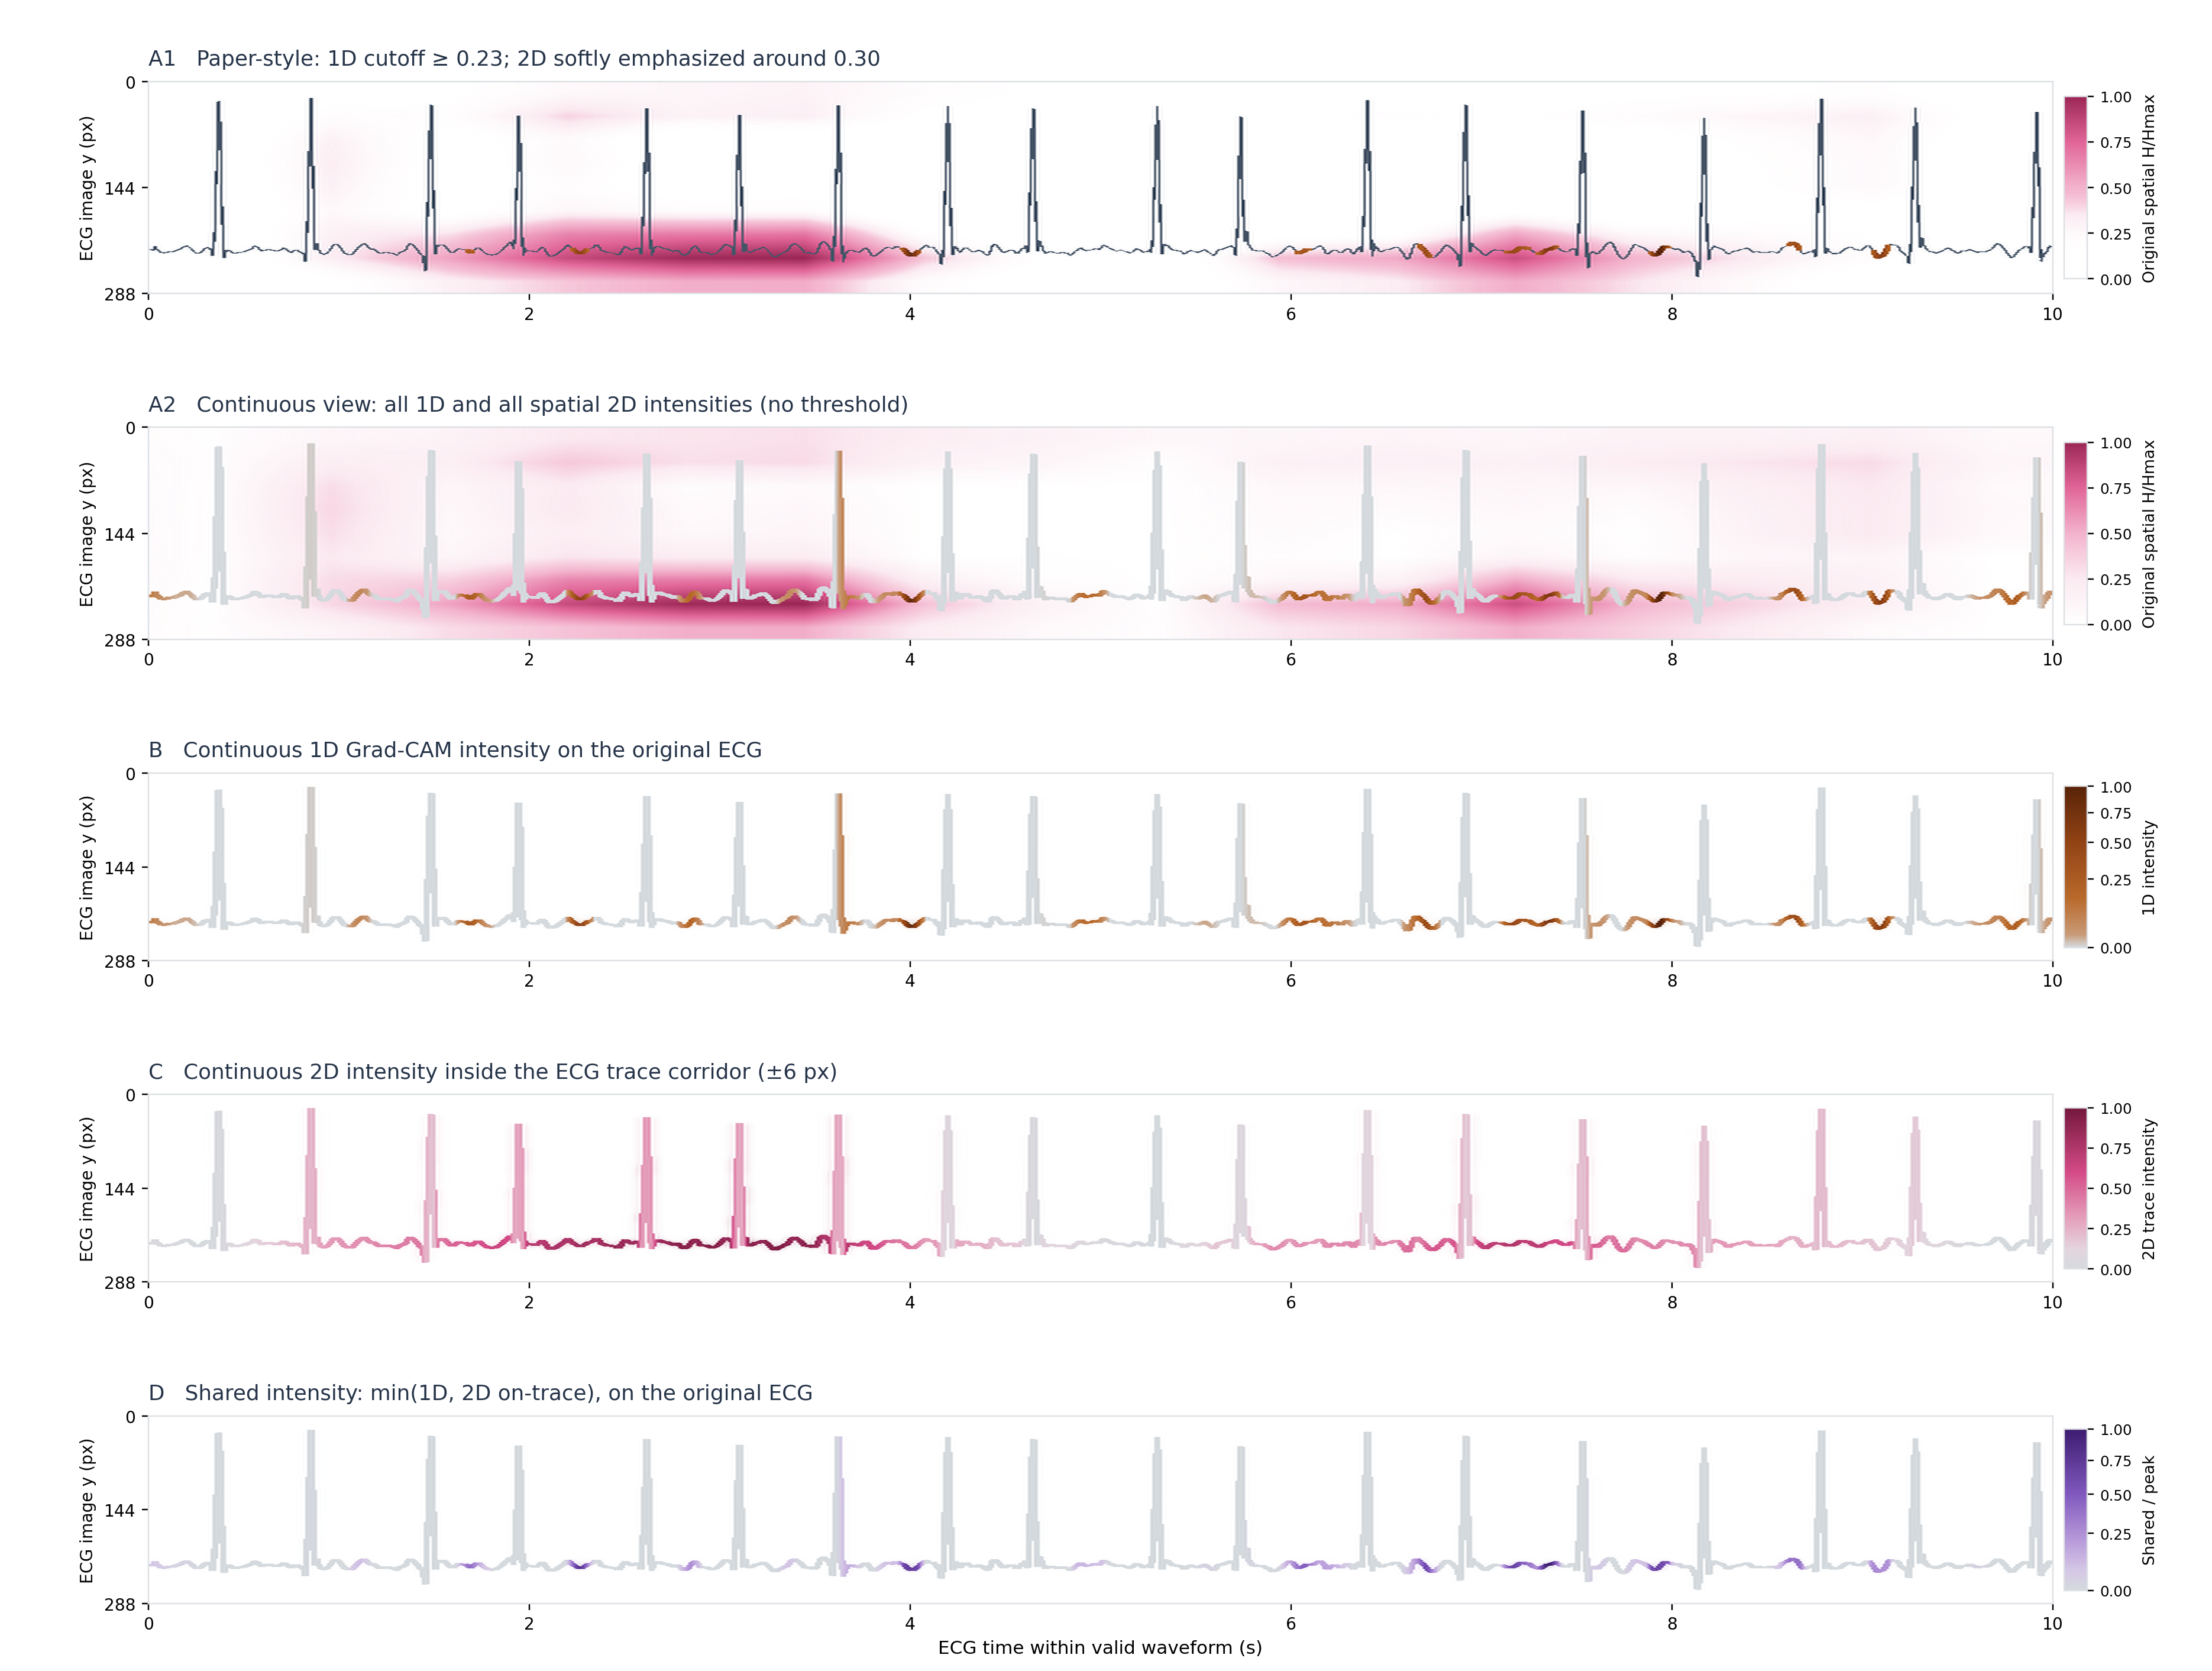

    O    Jw  spearman  dice15  dir_1D_dominant  dir_2D_dominant
0.287 0.167     0.062    0.37             12.5            9.142


In [6]:
display(Image(filename=str(ARCH / 'module1/ecg209_module1_panels.png'), width=900))
print(per[per.cohort_index == 209][['O', 'Jw', 'spearman', 'dice15', 'dir_1D_dominant', 'dir_2D_dominant']].round(3).to_string(index=False))

ECG 209 (AFib): (A1) anchor-style display with a 0.23 cut-off; (A2) the same without cut-off; (B) continuous 1D intensity;
(C) 2D intensity received by the waveform inside the ±6 px corridor; (D) shared intensity $\min(p,q)$. The Module 1 panels were produced by the Module 1 branch scripts
(`src/hpc_pipeline/02_gradcam_and_module1/`).

saved fig_module1_cohort


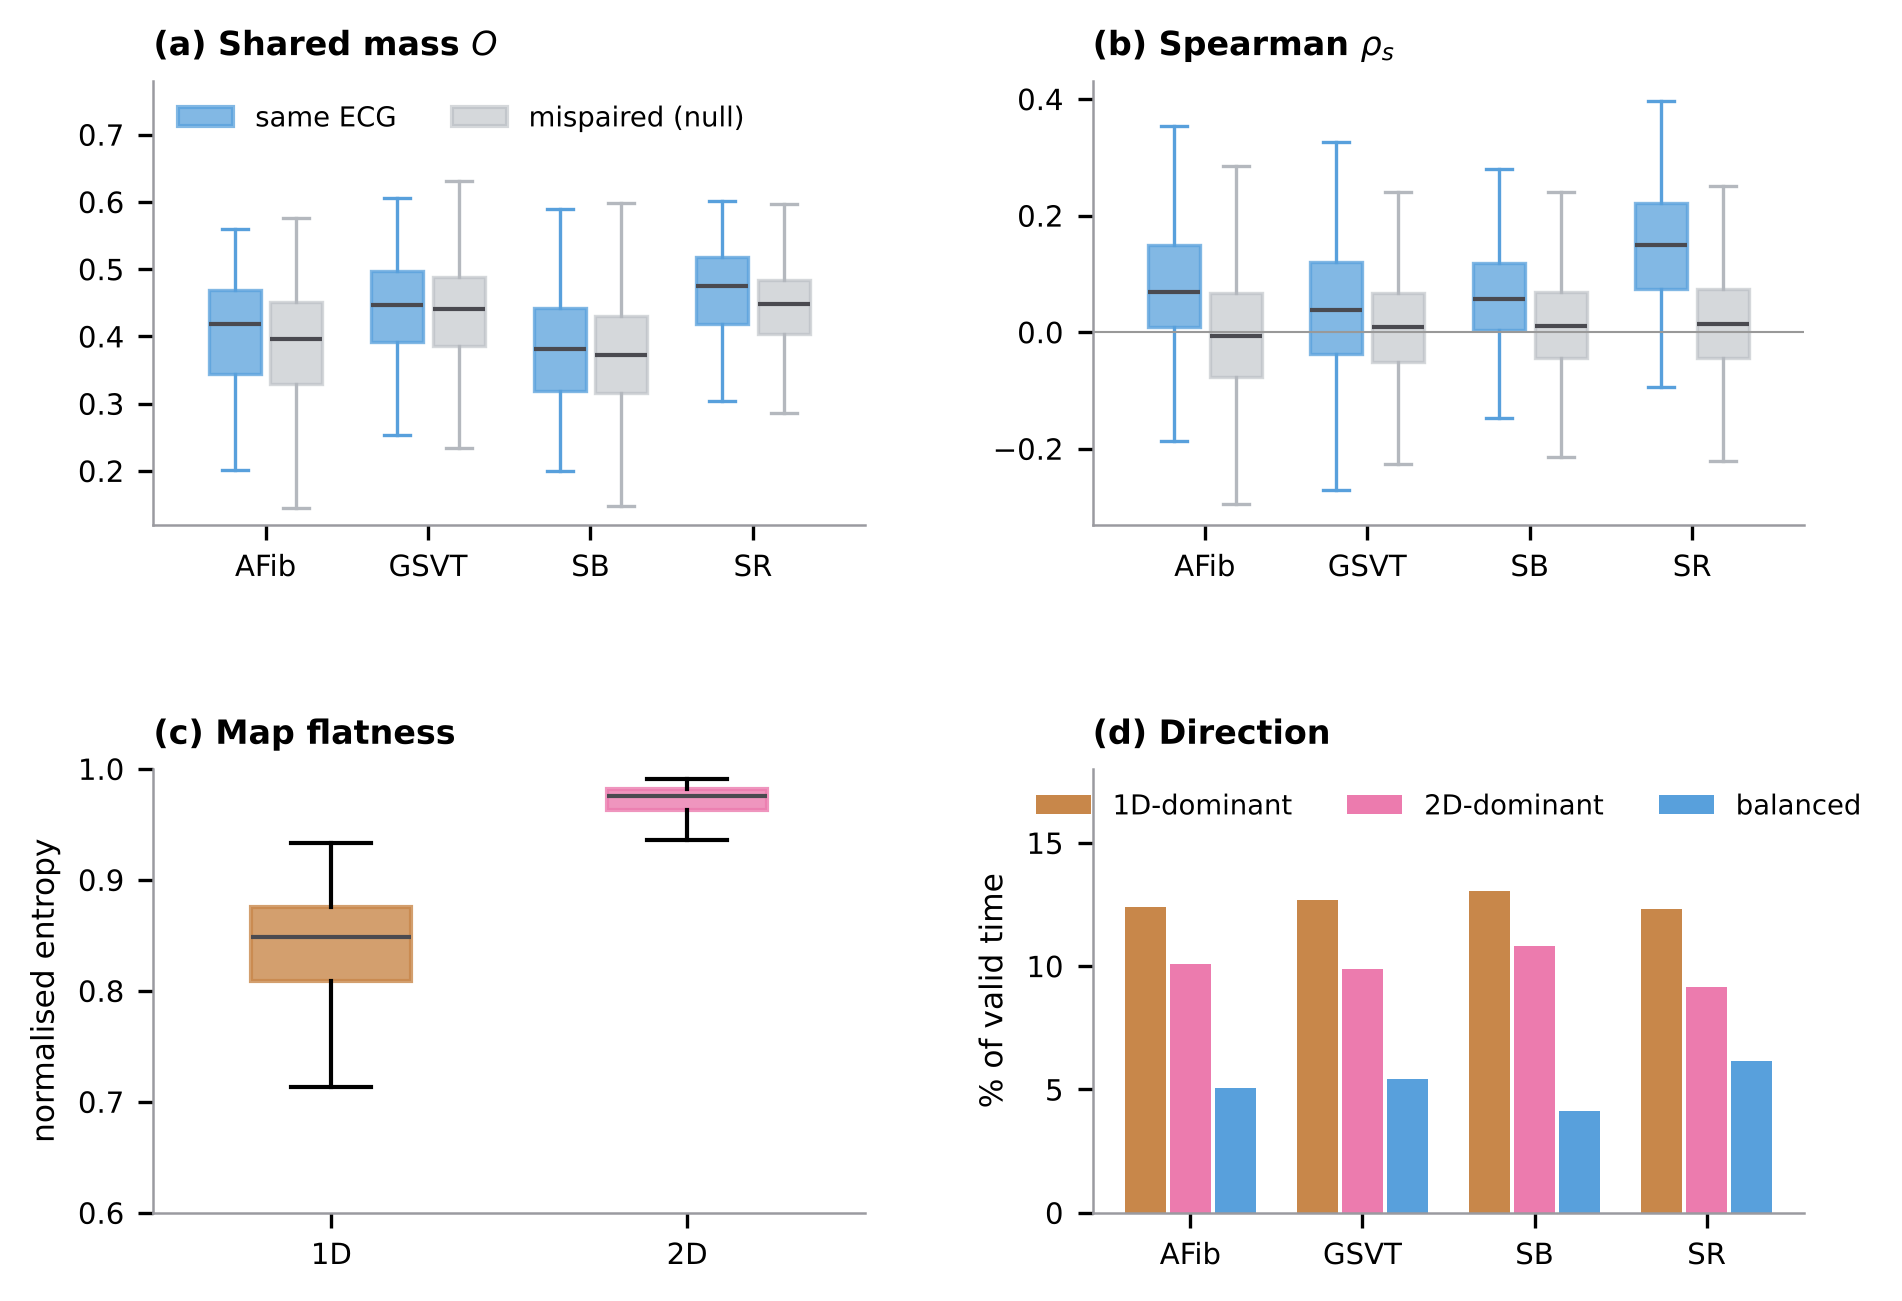

In [7]:
import dan_figures as F
per_fig = per.copy(); per_fig['both_correct'] = per_fig.both_correct.fillna(False).astype(bool)
F.fig_module1_cohort(per_fig, null, FIG)
show('fig_module1_cohort', 700)

## 4. Comparison with the anchor-style binary-mask agreement and projection sensitivity

The Module 1 branch first computed agreement after min–max scaling each map and treating the 2D map as a binary contact mask.
Below, the same recordings are summarised with that baseline, and the intensity-aware projection is compared across kernels.

,method,n,median weighted Jaccard,median Spearman,median Dice top-15%
0,binary-mask min–max (Module 1 branch),1033,0.154,0.090,0.173
1,intensity-aware mass (this work),939,0.267,0.071,0.160


saved fig_module1_minmax_baseline


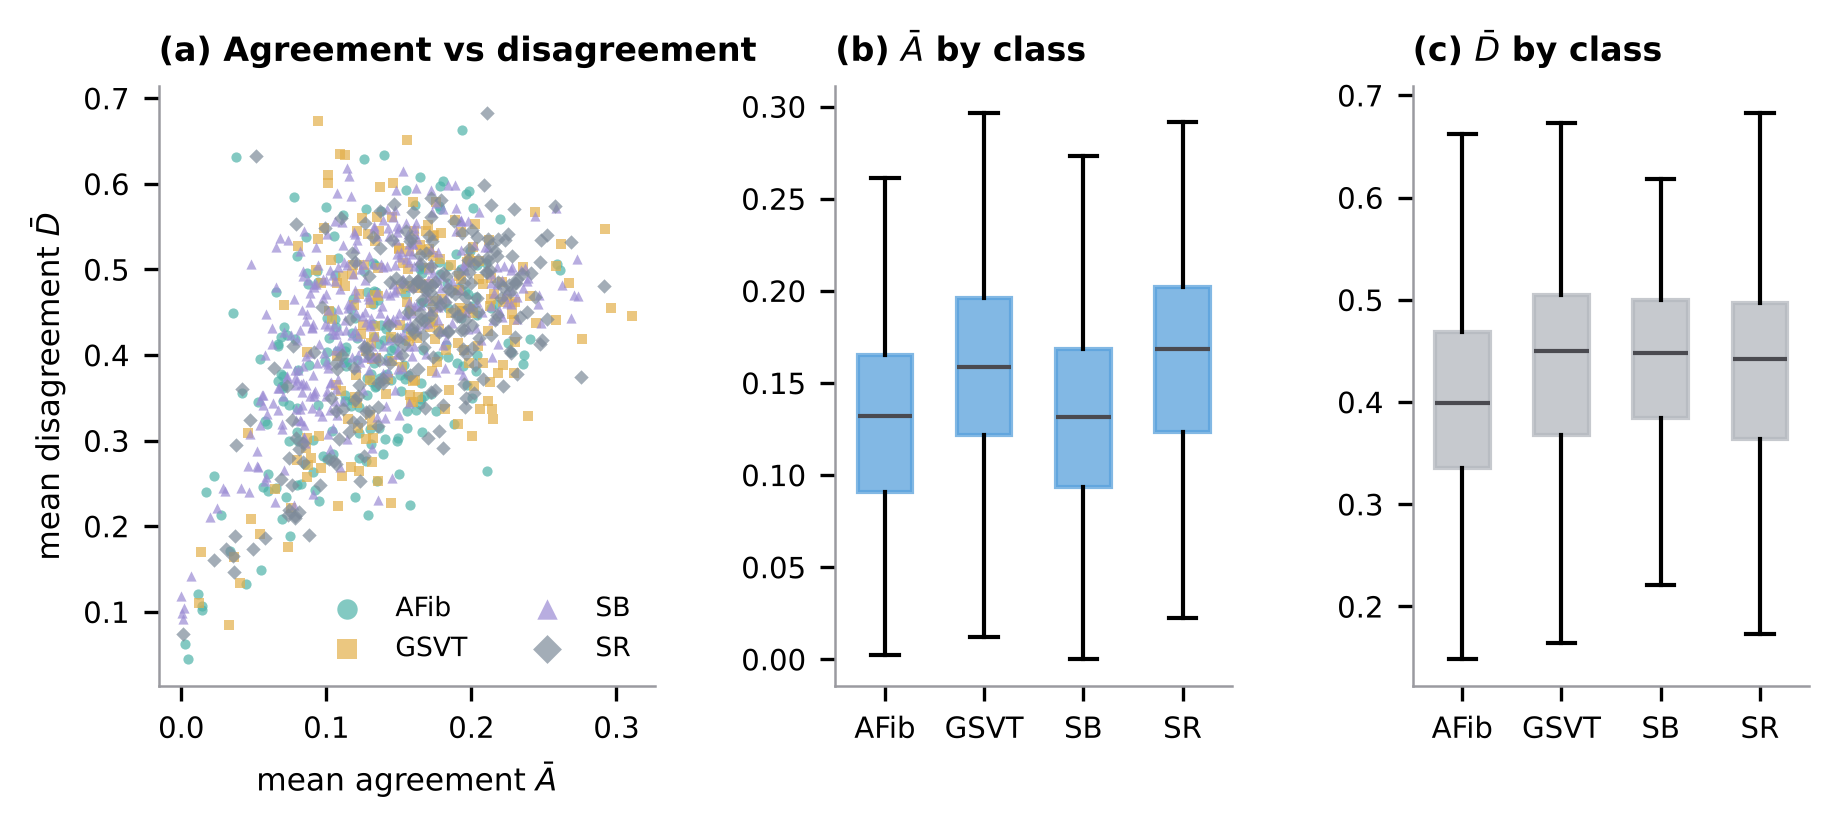

In [8]:
mm = pd.read_csv(ARCH / 'module1/minmax_agreement_shift0.csv')
ok = mm[(mm.degenerate_1d.astype(str) == 'False') & (mm.degenerate_2d.astype(str) == 'False')]
base_cmp = pd.DataFrame({
    'method': ['binary-mask min–max (Module 1 branch)', 'intensity-aware mass (this work)'],
    'n': [len(ok), len(prim)],
    'median weighted Jaccard': [ok.weighted_jaccard.median(), prim.Jw.median()],
    'median Spearman': [ok.spearman.median(), prim.spearman.median()],
    'median Dice top-15%': [ok.dice_top15.median(), prim.dice15.median()]})
base_cmp.to_csv(TAB / 'module1_baseline_comparison.csv', index=False)
display(base_cmp.round(3))
F.fig_m1_baseline(mm, FIG); show('fig_module1_minmax_baseline', 600)

In [9]:
proj = pd.read_csv(ARCH / 'module1/projection_summary.csv')
print('Sensitivity of the min–max baseline to the corridor half-width (px):')
proj.round(4)

Sensitivity of the min–max baseline to the corridor half-width (px):


,mask_size,mean_agreement,mean_disagreement,spearman,dice_top15,iou_top15,weighted_jaccard
0,6,0.1404,0.4234,0.0862,0.1765,0.0990,0.1561
1,13,0.1406,0.4241,0.0869,0.1769,0.0993,0.1560
2,24,0.1408,0.4250,0.0881,0.1780,0.1000,0.1560


**Summary of Module 1.** Cross-representation agreement is weak and only marginally above the mispairing null, the 2D explanation is broad,
and disagreement is directional rather than random. This is the evidence that a fused map cannot be read as "both models looked here" without testing.